In [8]:
#NCBI-də gen axtarışı
from Bio import Entrez

Entrez.email = "hasanovaa.ssssss@gmail.com"

query = '"Arabidopsis thaliana"[Organism] AND drought[All Fields]'

with Entrez.esearch(
    db="gene",
    term=query,
    retmax=20
) as handle:
    search_result = Entrez.read(handle)

gene_ids = search_result["IdList"]

print("Tapılan nəticələrin ümumi sayı:", search_result["Count"])
print("Götürülən gen ID-ləri:", gene_ids)

Tapılan nəticələrin ümumi sayı: 359
Götürülən gen ID-ləri: ['842859', '817857', '818903', '818982', '828652', '818199', '837763', '823721', '821902', '822061', '828714', '829541', '843244', '836259', '838518', '815949', '838883', '818614', '839341', '819174']


In [9]:
#Gen xülasələrini əldə etmək
import json
import pandas as pd
from Bio import Entrez

if not gene_ids:
    print("Gen tapılmadı. Axtarış sözlərini yoxlayın.")
else:
    with Entrez.esummary(
        db="gene",
        id=",".join(gene_ids),
        retmode="json"
    ) as handle:
        summary_data = json.load(handle)

    print("Məlumat uğurla alındı.")
    print("Nəticə açarları:", summary_data.keys())

Məlumat uğurla alındı.
Nəticə açarları: dict_keys(['header', 'result'])


In [10]:
#Cədvəl yaratmaq
if gene_ids:
    result_data = summary_data.get("result", {})
    rows = []

    for gene_id in result_data.get("uids", []):
        item = result_data.get(gene_id, {})

        if not isinstance(item, dict):
            continue

        rows.append({
            "gene_id": item.get("uid", gene_id),
            "symbol": item.get("name", ""),
            "description": item.get("description", "")
        })

    genes = pd.DataFrame(
        rows,
        columns=["gene_id", "symbol", "description"]
    )

    print(genes.head(10))
    print("Cədvəlin ölçüsü:", genes.shape)
else:
    genes = pd.DataFrame(
        columns=["gene_id", "symbol", "description"]
    )
    print("Cədvəl boşdur, çünki gen ID-si tapılmayıb.")

  gene_id  symbol                                        description
0  842859      FT  PEBP (phosphatidylethanolamine-binding protein...
1  817857    COP1    Transducin/WD40 repeat-like superfamily protein
2  818903    PIF4                   phytochrome interacting factor 4
3  818982    MPK6                                       MAP kinase 6
4  828652  DREB1A                   dehydration response element B1A
5  818199    ABI5  Basic-leucine zipper (bZIP) transcription fact...
6  837763  NRT1.1                            nitrate transporter 1.1
7  823721   PHOT1                                      phototropin 1
8  821902    ERF1                         ethylene response factor 1
9  822061    ABI3  AP2/B3-like transcriptional factor family protein
Cədvəlin ölçüsü: (20, 3)


In [11]:
#Cədvəli təmizlə və fayla yaz
if not genes.empty:
    genes = genes.drop_duplicates(subset="gene_id")
    genes = genes.fillna("")

    print("Unikal gen sayı:", genes["gene_id"].nunique())
    display(genes.head(10))

    genes.to_csv(
        "plant_stress_candidate_genes.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print("Cədvəl CSV faylına yazıldı.")
else:
    print("Saxlanılacaq məlumat yoxdur.")

Unikal gen sayı: 20


,gene_id,symbol,description
0,842859,FT,PEBP (phosphatidylethanolamine-binding protein...
1,817857,COP1,Transducin/WD40 repeat-like superfamily protein
2,818903,PIF4,phytochrome interacting factor 4
3,818982,MPK6,MAP kinase 6
4,828652,DREB1A,dehydration response element B1A
5,818199,ABI5,Basic-leucine zipper (bZIP) transcription fact...
6,837763,NRT1.1,nitrate transporter 1.1
7,823721,PHOT1,phototropin 1
8,821902,ERF1,ethylene response factor 1
9,822061,ABI3,AP2/B3-like transcriptional factor family protein


Cədvəl CSV faylına yazıldı.


In [13]:
#Məlumatları təmizləmək
genes = genes.drop_duplicates(subset="gene_id").copy()

for column in ["symbol", "description"]:
    genes[column] = genes[column].fillna("").astype(str).str.strip()

genes = genes[genes["gene_id"].astype(str).str.strip() != ""]

print("Təkrarlanmayan gen sayı:", len(genes))
print("Boş gen adlarının sayı:", (genes["symbol"] == "").sum())
print("Boş təsvirlərin sayı:", (genes["description"] == "").sum())

display(genes.head(10))

Təkrarlanmayan gen sayı: 20
Boş gen adlarının sayı: 0
Boş təsvirlərin sayı: 0


,gene_id,symbol,description,stress_keyword_match
0,842859,FT,PEBP (phosphatidylethanolamine-binding protein...,False
1,817857,COP1,Transducin/WD40 repeat-like superfamily protein,False
2,818903,PIF4,phytochrome interacting factor 4,False
3,818982,MPK6,MAP kinase 6,False
4,828652,DREB1A,dehydration response element B1A,False
5,818199,ABI5,Basic-leucine zipper (bZIP) transcription fact...,False
6,837763,NRT1.1,nitrate transporter 1.1,False
7,823721,PHOT1,phototropin 1,False
8,821902,ERF1,ethylene response factor 1,False
9,822061,ABI3,AP2/B3-like transcriptional factor family protein,False


In [16]:
#Quraqlıqla əlaqəli namizəd genləri seçmək
keywords = [
    "drought",
    "water",
    "stress",
    "abscisic",
    "salt",
    "heat",
    "dehydration",
    "osmotic",
    "desiccation",
    "response"
]

pattern = "|".join(keywords)

genes["stress_related"] = genes["description"].str.contains(
    pattern,
    case=False,
    na=False,
    regex=True
)

candidates = genes[genes["stress_related"]].copy()

print("Ümumi gen sayı:", len(genes))
print("Uyğun gələn genlərin sayı:", len(candidates))

display(candidates[["gene_id", "symbol", "description"]].head(15))

Ümumi gen sayı: 20
Uyğun gələn genlərin sayı: 3


,gene_id,symbol,description
4,828652,DREB1A,dehydration response element B1A
8,821902,ERF1,ethylene response factor 1
13,836259,TOC1,CCT motif -containing response regulator protein


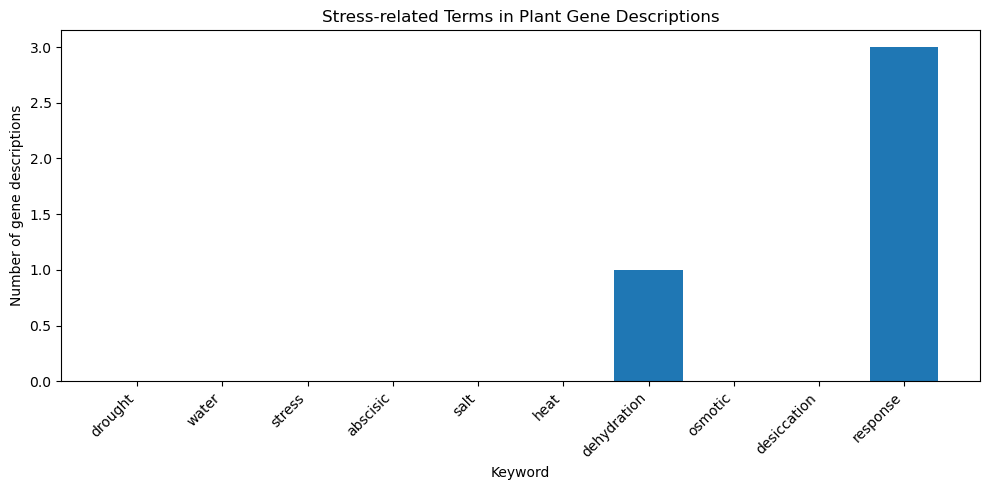

Açar sözlər üzrə nəticələr:
drought: 0
water: 0
stress: 0
abscisic: 0
salt: 0
heat: 0
dehydration: 1
osmotic: 0
desiccation: 0
response: 3


In [18]:
import matplotlib.pyplot as plt

keywords_to_plot = [
    "drought",
    "water",
    "stress",
    "abscisic",
    "salt",
    "heat",
    "dehydration",
    "osmotic",
    "desiccation",
    "response"
]

descriptions = genes["description"].fillna("").astype(str)

keyword_counts = {}

for word in keywords_to_plot:
    count = descriptions.str.contains(
        word,
        case=False,
        regex=False
    ).sum()

    keyword_counts[word] = count

plt.figure(figsize=(10, 5))

plt.bar(
    keyword_counts.keys(),
    keyword_counts.values()
)

plt.title("Stress-related Terms in Plant Gene Descriptions")
plt.xlabel("Keyword")
plt.ylabel("Number of gene descriptions")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("Açar sözlər üzrə nəticələr:")

for word, count in keyword_counts.items():
    print(f"{word}: {count}")